# 06. Random Forest Classifier

**Project** · Customer Churn Prediction  
**Problem type** · Classification

This dataset is synthetic and designed for education. Keep its predictions within the exercise. Any real-world financial, medical, safety, educational or employment decision requires independent evidence and validation.

Start with Sections 1–9 for your first model. Then try parameter tuning and the interview exercises. Run the code cells in order because each step uses results from earlier cells.

## 1. Introduction

A classification forest trains many trees on different versions of the customer data. Combining their outputs reduces sensitivity to any one tree. A churn model can summarize evidence from billing, contract and support history.

By the end, you can implement the pipeline, explain how it predicts and use holdout results to identify where it struggles.

## 2. Understand the Dataset

Churn log-odds rise with monthly contracts, manual payment, tickets, larger bills and short tenure. A monthly plan with at least five tickets adds an interaction term. Outcomes are sampled from the resulting sigmoid probabilities.

| Column | Type | Units or values | Meaning |
| --- | --- | --- | --- |
| `tenure_months` | integer | months | Time as a customer |
| `monthly_bill_usd` | decimal | USD/month | Monthly bill |
| `support_tickets` | integer | count | Number of recent support tickets |
| `contract_type` | string | Monthly, Annual or Two-year | Renewal term |
| `automatic_payment` | string | Yes or No | Whether automatic payment is enabled |
| `churn` | string | No Churn, Churn | Observed class label |

**Independent variables (X)** · `tenure_months`, `monthly_bill_usd`, `support_tickets`, `contract_type`, `automatic_payment`.

**Dependent variable (y)** · `churn` is the class to predict. The preview shows the first 10 rows, dimensions and stored types. Blank features, where present, are intentional.

In [ ]:
import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
os.environ.setdefault("OMP_NUM_THREADS", "2")

from pathlib import Path
import pandas as pd
from IPython.display import display

csv_name = "06_customer_churn.csv"
csv_path = Path("../datasets") / csv_name

# Also look in the project folder or the location used for Colab uploads.
if not csv_path.is_file():
    csv_path = Path("datasets") / csv_name
if not csv_path.is_file():
    csv_path = Path("Machine_Learning_Complete_Guide/datasets") / csv_name
if not csv_path.is_file():
    csv_path = Path(csv_name)

df = pd.read_csv(csv_path, keep_default_na=False, na_values=[""])
print("Dataset shape:", df.shape)
display(df.head(10))
display(df.dtypes)

## 3. Mathematical Understanding

For class $k$ and new row $x$, scikit-learn averages $\bar p_k(x)=(1/B)\sum_{b=1}^B p_{bk}(x)$. Here $B$ counts trees, $b$ identifies a tree, and $p_{bk}(x)$ is its probability for class $k$ from the reached leaf. The class with the largest average wins. This is soft voting. In hard voting a tree contributes only its winning label.

If three leaves give churn probabilities $0.20$, $0.65$ and $0.80$, their mean is $0.55$, which predicts Churn in a binary model with a 0.50 cutoff. A bootstrap sample of $n$ rows draws $n$ times with replacement from the $n$ training rows, so rows can appear repeatedly or be omitted.

[scikit-learn user guide](https://scikit-learn.org/stable/modules/ensemble.html#forest)

## 4. Working Principle

Make each bootstrap sample and fit a tree, considering a random subset of features at each split. Route the new customer through every tree. Average the leaf probabilities and use the largest average to choose a class. Randomizing both rows and candidate features helps avoid highly similar trees.

| Contributor | Churn probability |
| --- | --- |
| Tree A | 0.20 |
| Tree B | 0.65 |
| Tree C | 0.80 |
| Average | 0.55 |

**Workflow diagram**

`Raw input` → `Imputed numeric values and any category indicators` → `Averages class probabilities from randomized trees` → `Class prediction`.

## 5. Dataset Exploration

The first and last rows verify parsing. Shape and info reveal size, stored types and non-missing counts. Summary statistics show typical values, ranges and spread. Missingness and duplicate counts identify possible cleanup needs. The target plot shows class balance. Feature plots show variation. Pearson correlation measures linear association. The category target is excluded. The features and evaluation design are fixed before modeling.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
TARGET = "churn"
FEATURES = ["tenure_months","monthly_bill_usd","support_tickets","contract_type","automatic_payment"]
NUMERIC = ["tenure_months","monthly_bill_usd","support_tickets"]
CATEGORICAL = ["contract_type","automatic_payment"]
SEED = 42
LABELS = ["No Churn","Churn"]

In [ ]:
df.info()
display(df.head())
display(df.tail())
display(df.describe(include="all").T)
display(pd.DataFrame({"Missing": df.isna().sum(), "Missing %": 100 * df.isna().mean()}).round(1))
print("Exact duplicate rows:", df.duplicated().sum())
print("Repeated feature rows:", df.duplicated(subset=FEATURES).sum())

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   tenure_months      1500 non-null   int64  
 1   monthly_bill_usd   1470 non-null   float64
 2   support_tickets    1500 non-null   int64  
 3   contract_type      1470 non-null   str    
 4   automatic_payment  1500 non-null   str    
 5   churn              1500 non-null   str    
dtypes: float64(1), int64(2), str(3)
memory usage: 94.1 KB


,tenure_months,monthly_bill_usd,support_tickets,contract_type,automatic_payment,churn
0,55,85.93,2,Annual,Yes,Churn
1,21,38.51,1,Monthly,Yes,No Churn
2,19,40.87,4,Monthly,Yes,No Churn
3,6,106.21,2,Monthly,Yes,Churn
4,57,27.02,1,Monthly,Yes,No Churn


,tenure_months,monthly_bill_usd,support_tickets,contract_type,automatic_payment,churn
1495,59,53.80,3,Monthly,No,Churn
1496,50,120.09,2,Annual,Yes,Churn
1497,2,112.33,3,Annual,Yes,No Churn
1498,66,32.98,3,Monthly,Yes,Churn
1499,65,82.49,2,Monthly,Yes,No Churn


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
tenure_months,1500.0,NaN,NaN,NaN,40.354667,23.207411,1.0,20.0,39.0,61.0,80.0
monthly_bill_usd,1470.0,NaN,NaN,NaN,77.529231,32.932569,22.07,48.5025,78.025,105.87,134.95
support_tickets,1500.0,NaN,NaN,NaN,2.154667,1.465666,0.0,1.0,2.0,3.0,8.0
contract_type,1470,3,Monthly,781,NaN,NaN,NaN,NaN,NaN,NaN,NaN
automatic_payment,1500,2,Yes,887,NaN,NaN,NaN,NaN,NaN,NaN,NaN
churn,1500,2,No Churn,872,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Missing,Missing %
tenure_months,0,0.0
monthly_bill_usd,30,2.0
support_tickets,0,0.0
contract_type,30,2.0
automatic_payment,0,0.0
churn,0,0.0


Exact duplicate rows: 0
Repeated feature rows: 0


### Plot the target

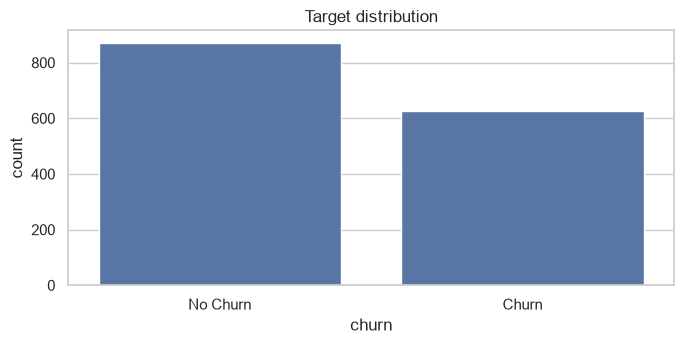

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.6))
sns.countplot(data=df, x=TARGET, order=LABELS, ax=ax)
ax.set_title("Target distribution")
fig.tight_layout()
plt.show()

### Look at the input features

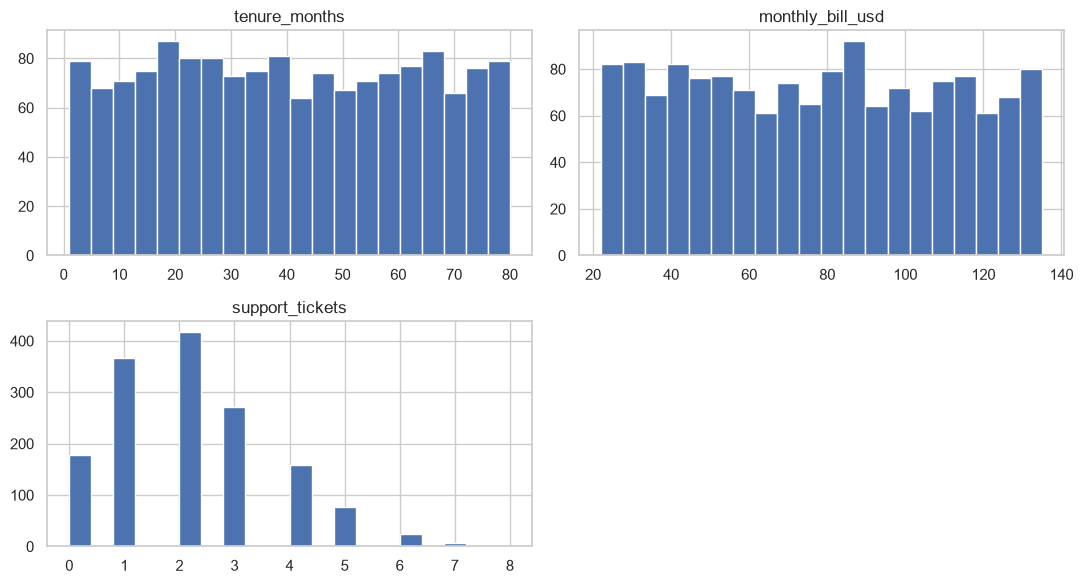

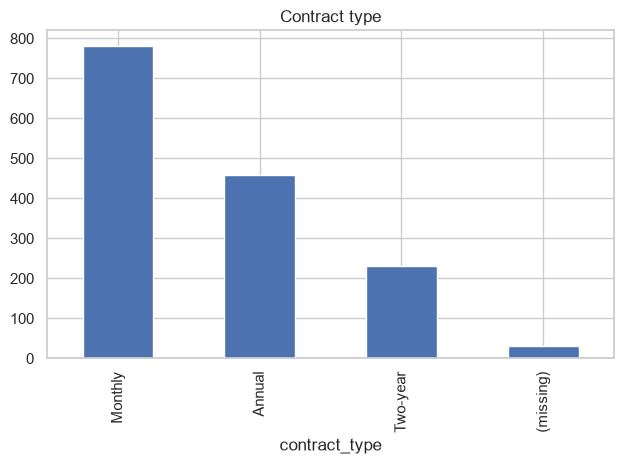

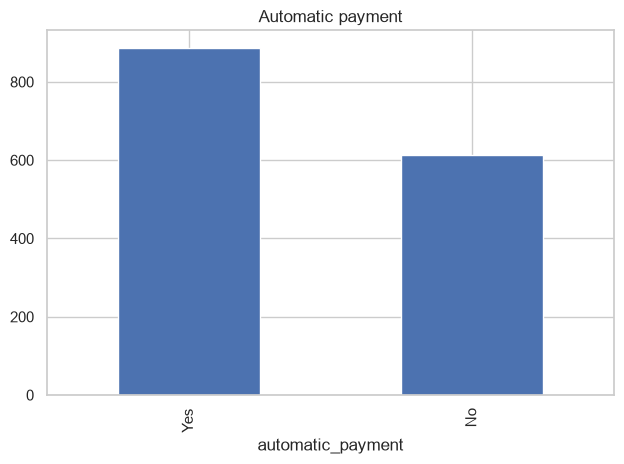

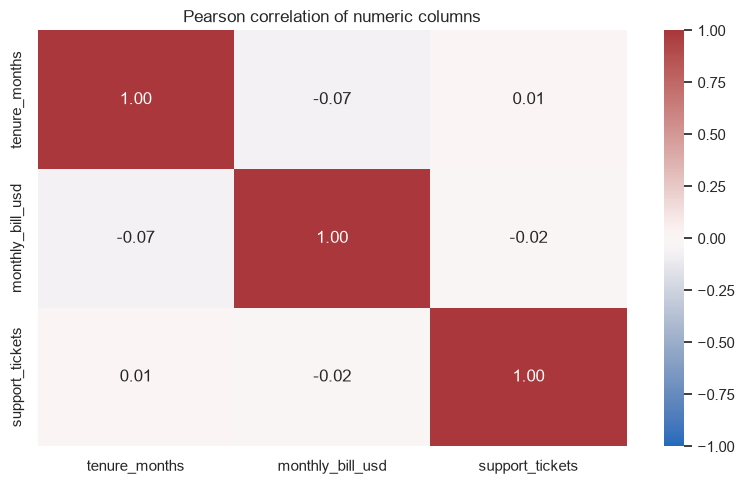

In [ ]:
df[NUMERIC].hist(figsize=(11, 6), bins=20)
plt.tight_layout()
plt.show()

df["contract_type"].fillna("(missing)").value_counts().plot.bar()
plt.title("Contract type")
plt.tight_layout()
plt.show()

df["automatic_payment"].fillna("(missing)").value_counts().plot.bar()
plt.title("Automatic payment")
plt.tight_layout()
plt.show()

correlation_columns = NUMERIC
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(df[correlation_columns].corr(), annot=True, fmt=".2f", cmap="vlag",
            center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Pearson correlation of numeric columns")
fig.tight_layout()
plt.show()

## 6. Data Preprocessing

Select the input columns and target explicitly. Stratification preserves approximate class proportions. The numeric branch fills blanks using training medians. The categorical branch fills blanks with the most common training level and one-hot encodes levels. An unseen level becomes an all-zero block. Tree splits use the ordering of values, so scaling is unnecessary. The pipeline fits each preprocessing step after the split and repeats it in each training fold.

Exact and feature-only duplicate counts are listed above. Identical measurements with distinct outcomes can represent legitimate observations.

### 1. Choose the inputs and target

In [ ]:
# X contains the inputs. y contains the answer for each row.
X = df[FEATURES]
label_codes = {'No Churn': 0, 'Churn': 1}
y = df[TARGET].map(label_codes)

### 2. Split the rows into training and test sets

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 1200
Test rows: 300


### 3. Prepare the columns

The next cell sets up the cleaning steps. They learn their values later, when you fit the model.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Fill blank numbers with the training median.
numeric_preprocess = SimpleImputer(strategy="median")

# Fill blank categories, then make one indicator column per category.
category_preprocess = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocess = ColumnTransformer(
    [
        ("numeric", numeric_preprocess, NUMERIC),
        ("categorical", category_preprocess, CATEGORICAL),
    ],
    verbose_feature_names_out=False,
)

## 7. Model Implementation

`n_estimators` is tree count, `max_depth` and `min_samples_leaf` control individual-tree complexity, and `max_features` controls how many candidates a split considers. The importance chart shows normalized training impurity decreases by encoded feature. Correlated signals can share or shift importance, and continuous features can have more opportunities for a split.

- The estimator import provides the algorithm implementation.
- `Pipeline` joins preprocessing and the model in execution order.
- `fit(X_train, y_train)` learns transformations and parameters from training rows.
- `predict(...)` applies the fitted steps to new rows. The first holdout row gives a preview before scoring the entire split.

### Create the model

In [ ]:
from sklearn.ensemble import RandomForestClassifier

estimator = RandomForestClassifier(
    n_estimators=100,
    max_depth=7,
    min_samples_leaf=8,
    max_features="sqrt",
    random_state=SEED,
    n_jobs=2
)
model = Pipeline([
    ("preprocess", preprocess),
    ("model", estimator),
])

### Fit on the training rows

In [ ]:
# Learn from the training rows.
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['tenure_months','monthly_bill_usd','support_tickets','contract_type', 'automatic_payment']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It

### Predict on the test rows

In [ ]:
# Predict using the held-out inputs.
predictions = model.predict(X_test)
display(X_test.head(1))
print("Example predicted class:", LABELS[predictions[0]])

,tenure_months,monthly_bill_usd,support_tickets,contract_type,automatic_payment
652,4,97.38,2,Monthly,Yes


Example predicted class: Churn


## 8. Model Evaluation

Let $TP$ count correctly predicted positives, $TN$ correctly predicted negatives, $FP$ false positives, $FN$ false negatives and $N$ all test rows. Higher values indicate better scores, subject to the baseline and the costs of different errors.

| Measure | Formula and interpretation |
| --- | --- |
| Accuracy | $(TP+TN)/N$ for binary outcomes, or the proportion of correct predictions for multiple classes. |
| Precision | $TP/(TP+FP)$. Of the predicted positives, how many really were positive? |
| Recall | $TP/(TP+FN)$. Of the actual positives, how many did the model catch? |
| F1 | $2PR/(P+R)$ for precision $P$ and recall $R$. It is their harmonic mean. |
| ROC-AUC | Area $\int_0^1 \mathrm{TPR}\,d(\mathrm{FPR})$, with $\mathrm{TPR}=TP/(TP+FN)$ and $\mathrm{FPR}=FP/(FP+TN)$. Binary AUC measures the chance of ranking a random positive above a random negative, counting ties as half. Around 0.5 corresponds to chance ranking. |
| Confusion matrix | Entry $(i,j)$ counts rows with actual class $i$ and predicted class $j$. A strong diagonal indicates correct classifications. Examine the off-diagonal cells for costly errors. |
| Classification report | Applies precision, recall and F1 per class. Support counts actual examples per class. Macro averaging weights classes equally, and weighted averaging uses support. |

The positive class is **Churn**. ROC-AUC ranks by its estimated probability. A prior-only classifier gives a baseline. A class with no positive predictions gets zero precision by convention.

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, ConfusionMatrixDisplay, RocCurveDisplay)

AVERAGE = "binary"
CLASS_IDS = np.arange(len(LABELS))

test_scores = model.predict_proba(X_test)[:, 1]

initial_metrics = {
    "Accuracy": accuracy_score(y_test, predictions),
    "Precision": precision_score(y_test, predictions, average=AVERAGE, zero_division=0),
    "Recall": recall_score(y_test, predictions, average=AVERAGE, zero_division=0),
    "F1": f1_score(y_test, predictions, average=AVERAGE, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_scores),
}
display(pd.Series(initial_metrics, name="Test score").round(3))

Accuracy     0.687
Precision    0.645
Recall       0.563
F1           0.602
ROC-AUC      0.736
Name: Test score, dtype: float64

### Compare with a simple baseline

In [ ]:
# A baseline knows the training class frequencies and sees no input features.
baseline = DummyClassifier(strategy="prior")
baseline_train = np.zeros((len(y_train), 1))
baseline_test = np.zeros((len(y_test), 1))
baseline.fit(baseline_train, y_train)

baseline_predictions = baseline.predict(baseline_test)
baseline_scores = baseline.predict_proba(baseline_test)[:, 1]

baseline_metrics = {
    "Accuracy": accuracy_score(y_test, baseline_predictions),
    "Precision": precision_score(y_test, baseline_predictions, average=AVERAGE, zero_division=0),
    "Recall": recall_score(y_test, baseline_predictions, average=AVERAGE, zero_division=0),
    "F1": f1_score(y_test, baseline_predictions, average=AVERAGE, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, baseline_scores),
}
display(pd.DataFrame([baseline_metrics, initial_metrics], index=["Baseline", "Model"]).round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC
Baseline,0.580,0.000,0.000,0.000,0.500
Model,0.687,0.645,0.563,0.602,0.736


### Read the results for each class

In [ ]:
print(classification_report(
    y_test, predictions, labels=CLASS_IDS, target_names=LABELS, zero_division=0
))

              precision    recall  f1-score   support

    No Churn       0.71      0.78      0.74       174
       Churn       0.65      0.56      0.60       126

    accuracy                           0.69       300
   macro avg       0.68      0.67      0.67       300
weighted avg       0.68      0.69      0.68       300



## 9. Visualizations

Read the confusion matrix by row for each actual class. Off-diagonal cells show the direction and size of confusions. The ROC curve shows the recall and false-positive trade-off across score thresholds.

The recorded impurity decrease ranks encoded features by how often and how usefully the fitted trees split on them. Correlation and differing split opportunities affect the ranking. One-hot levels appear as separate bars.

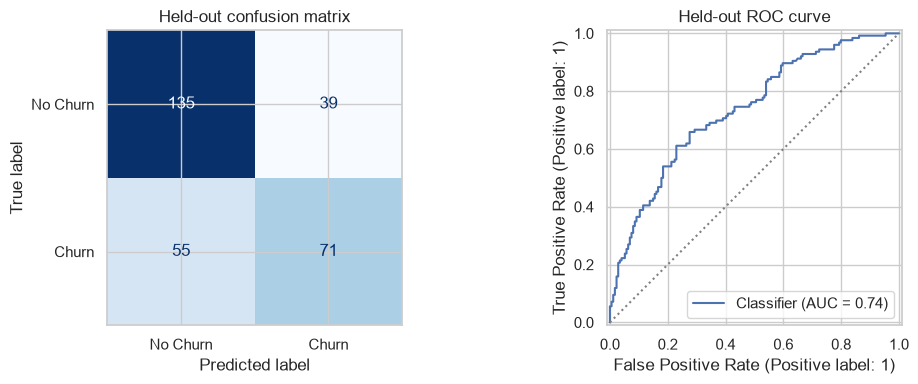

In [ ]:
fig, (ax, roc_ax) = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, predictions, labels=CLASS_IDS, display_labels=LABELS,
                                        colorbar=False, cmap="Blues", ax=ax)
ax.set_title("Held-out confusion matrix")
RocCurveDisplay.from_predictions(y_test, test_scores, pos_label=1, ax=roc_ax)
roc_ax.plot([0, 1], [0, 1], linestyle=":", color="grey")
roc_ax.set_title("Held-out ROC curve")
fig.tight_layout()
plt.show()

### A closer look at this model

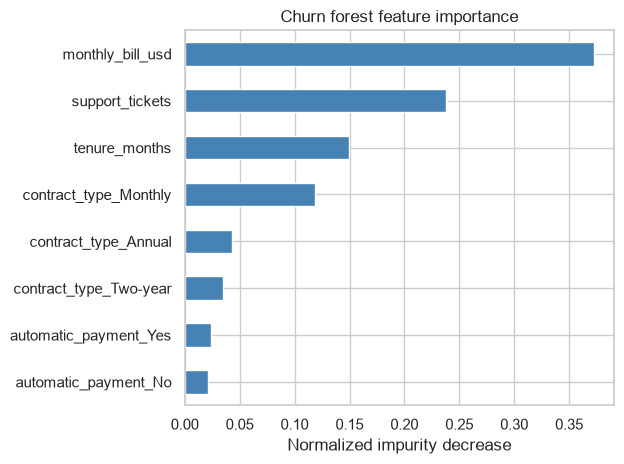

In [ ]:
importance = pd.Series(
    model.named_steps["model"].feature_importances_,
    index=model.named_steps["preprocess"].get_feature_names_out(),
)
ax = importance.sort_values().plot.barh(color="steelblue")
ax.set(xlabel="Normalized impurity decrease", title="Churn forest feature importance")
plt.tight_layout()
plt.show()

## 10. Hyperparameter Tuning

GridSearchCV tries the grid with three shuffled stratified folds within the training data. Each candidate gets a freshly fitted pipeline per fold. Rank by positive-class F1. `refit=True` fits the winner on all training rows. Use the CV ranks to choose parameters and the holdout to report performance.

`n_estimators` is tree count, `max_depth` and `min_samples_leaf` control individual-tree complexity, and `max_features` controls how many candidates a split considers. The importance chart shows normalized training impurity decreases by encoded feature. Correlated signals can share or shift importance, and continuous features can have more opportunities for a split.

[GridSearchCV documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)

### Set up the candidate settings

In [ ]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {"model__n_estimators": [60, 120], "model__max_depth": [4, 9], "model__max_features": ["sqrt", 1.0]}
validation = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
search = GridSearchCV(model, param_grid, scoring="f1", cv=validation,
                      refit=True, n_jobs=1, error_score="raise")

### Search using training rows

In [ ]:
search.fit(X_train, y_train)
tuned_model = search.best_estimator_
results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
results["Mean CV F1"] = results["mean_test_score"]
print("Best training-CV parameters:", search.best_params_)
display(results[["rank_test_score", "Mean CV F1", "std_test_score", "params"]].head().round(3))

Best training-CV parameters: {'model__max_depth': 9, 'model__max_features': 1.0, 'model__n_estimators': 120}


,rank_test_score,Mean CV F1,std_test_score,params
7,1,0.612,0.007,"{'model__max_depth': 9, 'model__max_features':..."
5,2,0.610,0.007,"{'model__max_depth': 9, 'model__max_features':..."
6,3,0.608,0.002,"{'model__max_depth': 9, 'model__max_features':..."
4,4,0.596,0.015,"{'model__max_depth': 9, 'model__max_features':..."
0,5,0.586,0.019,"{'model__max_depth': 4, 'model__max_features':..."


### Compare the models on the test set

In [ ]:
tuned_predictions = tuned_model.predict(X_test)
tuned_scores = tuned_model.predict_proba(X_test)[:, 1]

tuned_metrics = {
    "Accuracy": accuracy_score(y_test, tuned_predictions),
    "Precision": precision_score(y_test, tuned_predictions, average=AVERAGE, zero_division=0),
    "Recall": recall_score(y_test, tuned_predictions, average=AVERAGE, zero_division=0),
    "F1": f1_score(y_test, tuned_predictions, average=AVERAGE, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, tuned_scores),
}
comparison = pd.DataFrame(
    [baseline_metrics, initial_metrics, tuned_metrics],
    index=["Baseline", "First model", "Tuned model"],
)
display(comparison.round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC
Baseline,0.580,0.000,0.000,0.000,0.500
First model,0.687,0.645,0.563,0.602,0.736
Tuned model,0.683,0.626,0.611,0.618,0.726


## 11. Real-World Prediction

Pass three new examples to the CV-selected pipeline. The result shows the estimated probability of each class. Read those estimates in the context of the synthetic population.

### Enter three new examples

In [ ]:
examples = pd.DataFrame([
    [5, 116, 6, 'Monthly', 'No'],
    [50, 54, 0, 'Two-year', 'Yes'],
    [19, 82, 3, 'Annual', 'No'],
], columns=FEATURES)
display(examples)

,tenure_months,monthly_bill_usd,support_tickets,contract_type,automatic_payment
0,5,116,6,Monthly,No
1,50,54,0,Two-year,Yes
2,19,82,3,Annual,No


### Make predictions

In [ ]:
sample_inputs = examples
prediction_model = tuned_model
sample_predictions = prediction_model.predict(sample_inputs)
example_output = examples.copy()
example_output["Scenario"] = ["New customer with frequent support contact","Long-tenure customer with automatic payment","Mid-tenure annual customer"]
probabilities = prediction_model.predict_proba(sample_inputs)
example_output["Predicted class"] = np.take(LABELS, sample_predictions)

# Each row contains the class probabilities for one new example.
probability_table = pd.DataFrame(probabilities.round(3), columns=LABELS)
probability_table = probability_table.add_prefix("P(").add_suffix(")")
example_output = pd.concat([example_output, probability_table], axis=1)
display(example_output)

,tenure_months,monthly_bill_usd,support_tickets,contract_type,automatic_payment,Scenario,Predicted class,P(No Churn),P(Churn)
0,5,116,6,Monthly,No,New customer with frequent support contact,Churn,0.152,0.848
1,50,54,0,Two-year,Yes,Long-tenure customer with automatic payment,No Churn,0.891,0.109
2,19,82,3,Annual,No,Mid-tenure annual customer,No Churn,0.553,0.447


## 12. Limitations and Advantages

Forests capture interactions and typically reduce the variance of a single tree. They cost more time and memory and have weaker per-row explanations. Shallow trees can underfit, while deep trees may learn unstable patterns in small or noisy samples even after averaging. Use a forest as a nonlinear tabular baseline. Consider a simpler model where probabilities need easy auditing or direct attribution.

## 13. Interview Preparation

### A. 30-second explanation

> I predicted synthetic churn with a random forest using tenure, billing, support and contract data. Each tree sees bootstrap rows and random candidate features, and the classifier averages leaf probabilities. I used class-specific scores and ROC-AUC on a holdout and treated impurity importance as a model diagnostic.

### B. 90-second technical explanation

> I predicted synthetic churn with a random forest using tenure, billing, support and contract data. Each tree sees bootstrap rows and random candidate features, and the classifier averages leaf probabilities. I used class-specific scores and ROC-AUC on a holdout and treated impurity importance as a model diagnostic. My target was churn, and the inputs were tenure months, monthly bill usd, support tickets, contract type, automatic payment. Make each bootstrap sample and fit a tree, considering a random subset of features at each split. Route the new customer through every tree. Average the leaf probabilities and use the largest average to choose a class. Randomizing both rows and candidate features helps avoid highly similar trees. I held out 20% of the rows and fitted preprocessing within each training fold. I compared F1 and ROC-AUC with a prior baseline and read the confusion matrix to identify the classes that were easiest to confuse. The inputs and labels were generated for teaching, so the holdout performance describes this exercise. For real data I would confirm which inputs are available at prediction time and build a split that reflects where the model will be used.

### C. Ten technical questions

1. **What is bagging?** Combining models fitted on bootstrap samples.
2. **How is a random forest different from plain tree bagging?** It also randomizes which features are considered at splits.
3. **Are trees fitted sequentially?** They can be fitted independently in a random forest.
4. **Why do less correlated trees help?** Averaging cancels more of the individual errors.
5. **What is out-of-bag data?** Rows omitted by the bootstrap sample for a given tree.
6. **Does this classifier use hard voting?** Scikit-learn averages per-tree class probabilities.
7. **What does max_features control?** How many candidate features can be considered at a split.
8. **What does impurity importance summarize?** Accumulated weighted criterion reduction assigned to splits on a feature.
9. **Why can importance be biased?** Continuous or high-cardinality inputs offer more potential splits.
10. **What does adding trees change?** It usually stabilizes estimates and increases cost, with diminishing returns.

### D. Five scenario questions

1. **A single tree changes a lot with new samples. What would you try?** Average diverse trees and measure how validation variability changes.
2. **Churn probabilities are too extreme. What would you measure?** Use a calibration curve and evaluate recalibration on independent training-validation data.
3. **Monthly plans dominate the importance chart. Can you conclude they cause churn?** No. The importance describes predictive use within this fitted model.
4. **Churn is rare and interventions costly. How do you evaluate?** Measure precision and recall at candidate thresholds using validation, then evaluate once on holdout.
5. **Billing and plan tier overlap strongly. What happens to importance?** Either can substitute for the other, so importance may be shared or unstable.

### E. Three common mistakes

- Calling soft voting majority voting without qualification. Explain probability averaging.
- Using impurity importance as a causal ranking. Treat it as descriptive.
- Evaluating only accuracy. Inspect churn recall and precision.

### F. Complete project explanation

Use the measured scores in a short project walkthrough. Start with the problem, explain the pipeline and close with what the evaluation can support. This cell inserts results from the current run.

In [ ]:
from IPython.display import Markdown

summary = (
    "I built a supervised classification project for customer churn prediction using Random Forest Classifier. I generated 1,500 synthetic observations and used tenure months, monthly bill usd, support tickets, contract type, automatic payment to predict churn. I used a holdout and a preprocessing pipeline fitted within training folds. I compared the selected estimator with a simple baseline. "
    f"On the holdout, the CV-selected model reached {tuned_metrics['F1']:.3f} F1 for Churn, versus "
    f"{baseline_metrics['F1']:.3f} for the baseline, with ROC-AUC {tuned_metrics['ROC-AUC']:.3f}. "
    "I used impurity importance to see which encoded churn features the forest split on most usefully. These results apply to the synthetic data and should be validated on representative observations before practical use."
)
display(Markdown("> " + summary))

> I built a supervised classification project for customer churn prediction using Random Forest Classifier. I generated 1,500 synthetic observations and used tenure months, monthly bill usd, support tickets, contract type, automatic payment to predict churn. I used a holdout and a preprocessing pipeline fitted within training folds. I compared the selected estimator with a simple baseline. On the holdout, the CV-selected model reached 0.618 F1 for Churn, versus 0.000 for the baseline, with ROC-AUC 0.726. I used impurity importance to see which encoded churn features the forest split on most usefully. These results apply to the synthetic data and should be validated on representative observations before practical use.